# Curvas de incertidumbre sobre la probabilidad, por duración y frente al SEED base

Preguntas de la reunión con el tutor:

1. **Dinámica conjunta**: ¿cómo se mueve la curva de incertidumbre u(t) junto con la de probabilidad p(t)?
2. **Duración**: ¿cómo se distribuye la incertidumbre en husos **cortos, medianos y largos**?
3. **Pair plots**: ¿la incertidumbre de nuestros métodos (Deep Ensemble, Neural Process) es la misma que la del **SEED base**, o sea una "suma cero", o **rescata algo** que el SEED no ve?

**Eventos**: se clasifican según el **SEED base**, el modelo original congelado:

- **TP** y **FN** (incluye los pares con IoU < 0.2): se miden en el tramo **anotado**, así que su duración es la del huso.
- **FP**: se mide en el tramo **predicho**.
- **TN**: ventanas al azar de 0.75 s (la duración mediana de un huso), a más de 1 s de cualquier huso anotado o detección de SEED.

**Duración** (dos cortes, cerca de los terciles de los husos anotados, 0.62 y 0.90 s): **corto** < 0.6 s ≤ **mediano** < 0.9 s ≤ **largo**.

**Incertidumbres** (en bits):

| Modelo | Medidas |
|---|---|
| SEED base | `u SEED` = entropía de su probabilidad. Al ser un solo modelo, solo tiene la parte aleatoria. |
| Deep Ensemble | `u total DE`, `aleatoria DE`, `MI DE` (epistémica: desacuerdo entre los 5 SEED) |
| Neural Process | `u total NP`, `MI NP` (epistémica: desacuerdo entre las 16 muestras de z) |

Por evento se usa el **promedio** de u dentro del evento. La **masa** de incertidumbre es el **área bajo u(t)** dentro del evento (bit·s).

Todo es sobre test, 15 folds. No se entrena nada y no se lee el EEG crudo: solo las predicciones guardadas. Código: `src/eeg_uq/uncertainty_dynamics.py`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import spearmanr

_candidates = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next((p for p in _candidates if (p / 'configs' / 'default.yaml').exists()), Path.cwd())
if str(REPO_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / 'src'))
from eeg_uq import uncertainty_dynamics as ud
from eeg_uq.metrics import DURATION_THRESHOLD, SAMPLE_RATE_HZ

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 250)


def show(figure):
    display(figure)
    plt.close(figure)

REFRESH = False  # True recalcula desde los NPZ (~1 minuto)
result = ud.run_all(refresh=REFRESH)
events = result['events']
OFFSETS = result['offsets_s']
MODEL_COLORS = {'SEED': '#52514e', 'DE': '#2a78d6', 'NP': '#eb6834'}
TYPE_COLORS = {'TP': '#2a78d6', 'FN': '#c0392b', 'FP': '#eb6834', 'TN': '#a0a0a0'}
DURATION_COLORS = {'corto': '#e8b04a', 'mediano': '#1baf7a', 'largo': '#4a3aa7'}
display(events.groupby(['tipo', 'clase duración']).size().unstack().reindex(ud.EVENT_TYPES).fillna(0).astype(int))

clase duración,corto,largo,mediano,—
tipo,,,,
TP,3035,5018,5142,0
FN,1726,352,750,0
FP,1486,308,888,0
TN,0,0,0,6741


## 1. La curva de incertidumbre sobre la de probabilidad

### 1.1 Ejemplos

Evaluación 0, fold 0. En cada ejemplo hay tres paneles:

- **Probabilidad** de SEED, DE y NP, con el umbral 0.425.
- **Incertidumbre total** de cada modelo.
- **Incertidumbre epistémica** (MI) del DE y del NP.

Verde = huso anotado; gris = detección del SEED base. Los ejemplos se eligen cerca de la duración mediana de su grupo.

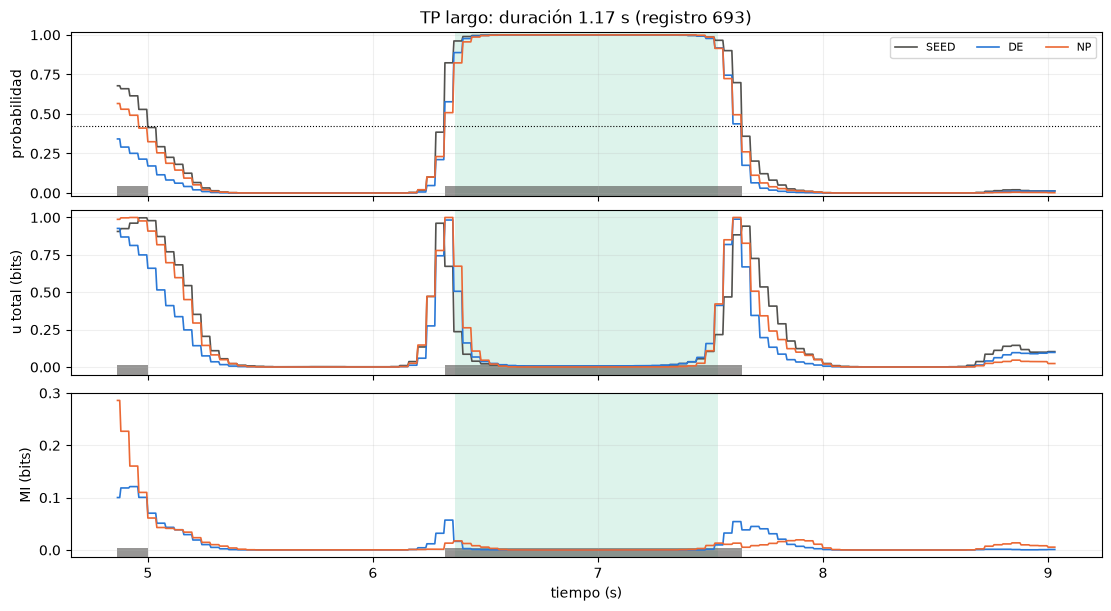

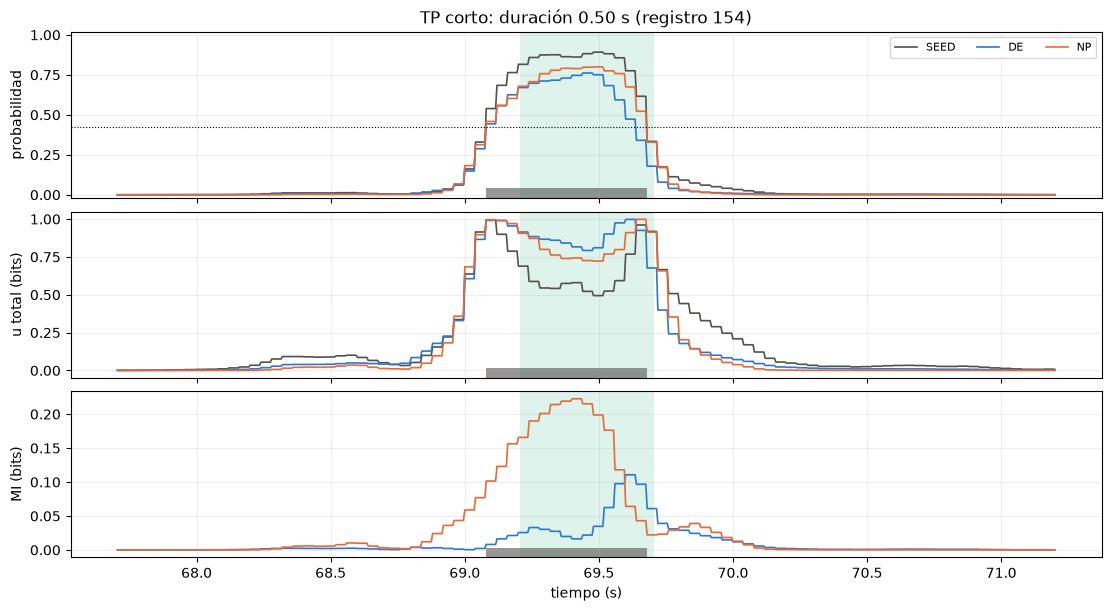

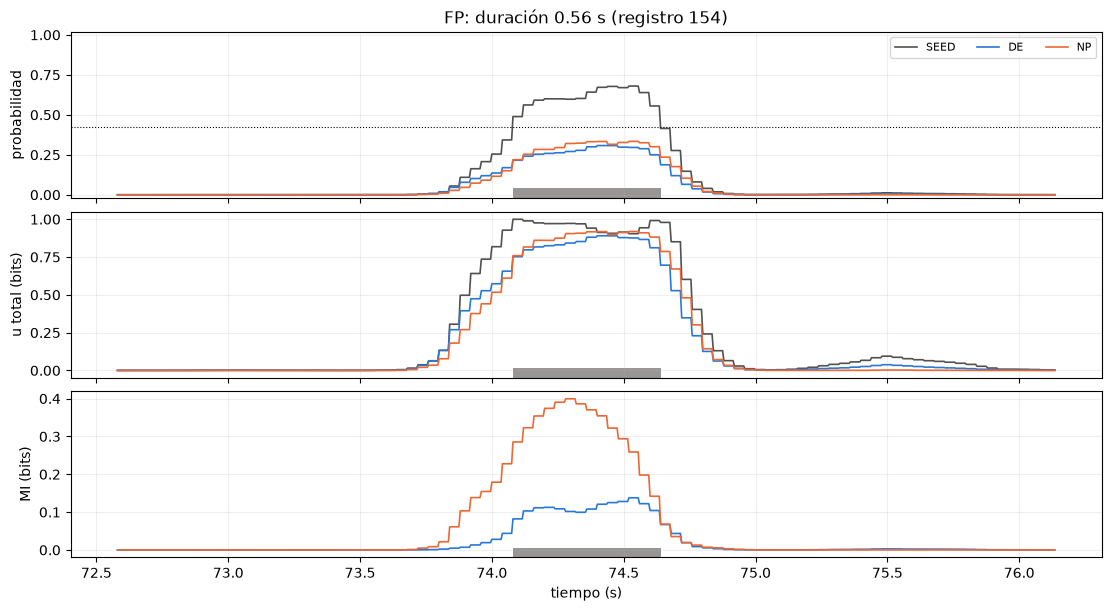

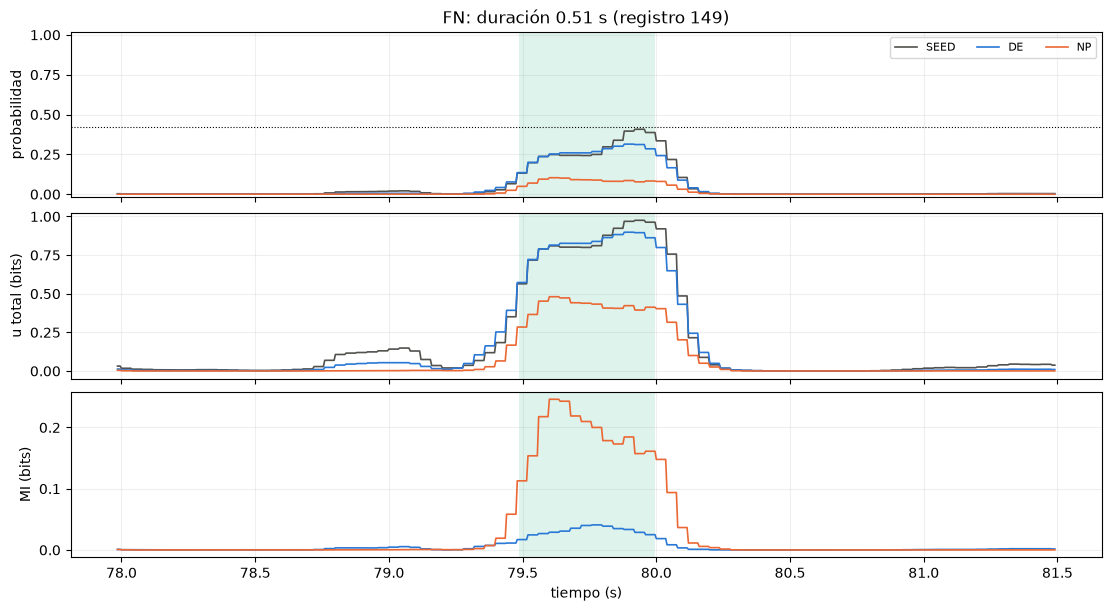

In [2]:
fold = ud.fold_series(0, 0)
spans = ud.base_events(fold, 0, 0)
fold_events = events[(events['evaluación'] == 0) & (events['fold'] == 0)]
series = fold['series']
PAD = int(1.5 * SAMPLE_RATE_HZ)


def pick(kind, cls=None):
    part = fold_events[fold_events['tipo'] == kind]
    if cls is not None:
        part = part[part['clase duración'] == cls]
    target = part['duración (s)'].median()
    return part.iloc[(part['duración (s)'] - target).abs().argsort().iloc[0]]


def spans_of(mask_row, lo, hi):
    edges = np.flatnonzero(np.diff(np.r_[0, mask_row[lo:hi] > 0, 0].astype(int)))
    return [(lo + a, lo + b) for a, b in zip(edges[::2], edges[1::2])]


def plot_example(event, title):
    row, lo = int(event['fila']), max(0, int(event['inicio']) - PAD)
    hi = min(series['p SEED'].shape[1], int(event['fin']) + PAD)
    t = np.arange(lo, hi) / SAMPLE_RATE_HZ
    fig, axes = plt.subplots(3, 1, figsize=(11, 6), sharex=True, constrained_layout=True)
    panels = [
        ('probabilidad', [('p SEED', 'SEED'), ('p DE', 'DE'), ('p NP', 'NP')]),
        ('u total (bits)', [('u SEED', 'SEED'), ('u total DE', 'DE'), ('u total NP', 'NP')]),
        ('MI (bits)', [('MI DE', 'DE'), ('MI NP', 'NP')]),
    ]
    for ax, (label, lines) in zip(axes, panels):
        for a, b in spans_of(fold['y_true'][row], lo, hi):
            ax.axvspan(a / SAMPLE_RATE_HZ, b / SAMPLE_RATE_HZ, color='#1baf7a', alpha=0.15, lw=0)
        for a, b in spans_of(fold['seed_pred'][row], lo, hi):
            ax.axvspan(a / SAMPLE_RATE_HZ, b / SAMPLE_RATE_HZ, ymin=0.0, ymax=0.06, color='#52514e', alpha=0.6, lw=0)
        for name, model in lines:
            ax.plot(t, series[name][row, lo:hi], color=MODEL_COLORS[model], lw=1.2, label=model)
        ax.set_ylabel(label)
        ax.grid(alpha=0.2)
    axes[0].axhline(DURATION_THRESHOLD, color='black', ls=':', lw=0.8)
    axes[0].set_ylim(-0.02, 1.02)
    axes[0].legend(loc='upper right', fontsize=8, ncol=3)
    axes[-1].set_xlabel('tiempo (s)')
    axes[0].set_title(f"{title}: duración {event['duración (s)']:.2f} s (registro {int(event['registro'])})")
    show(fig)


for kind, cls, title in [('TP', 'largo', 'TP largo'), ('TP', 'corto', 'TP corto'), ('FP', None, 'FP'), ('FN', None, 'FN')]:
    plot_example(pick(kind, cls), title)

### 1.2 Dinámica promedio: alineada al inicio y al fin del evento

Todos los TP, FN y FP de los 15 folds se alinean en su **inicio** (izquierda) y en su **fin** (derecha), y se promedia cada curva. Línea continua = probabilidad; línea punteada = incertidumbre total. El tiempo 0 es el inicio o el fin del evento.

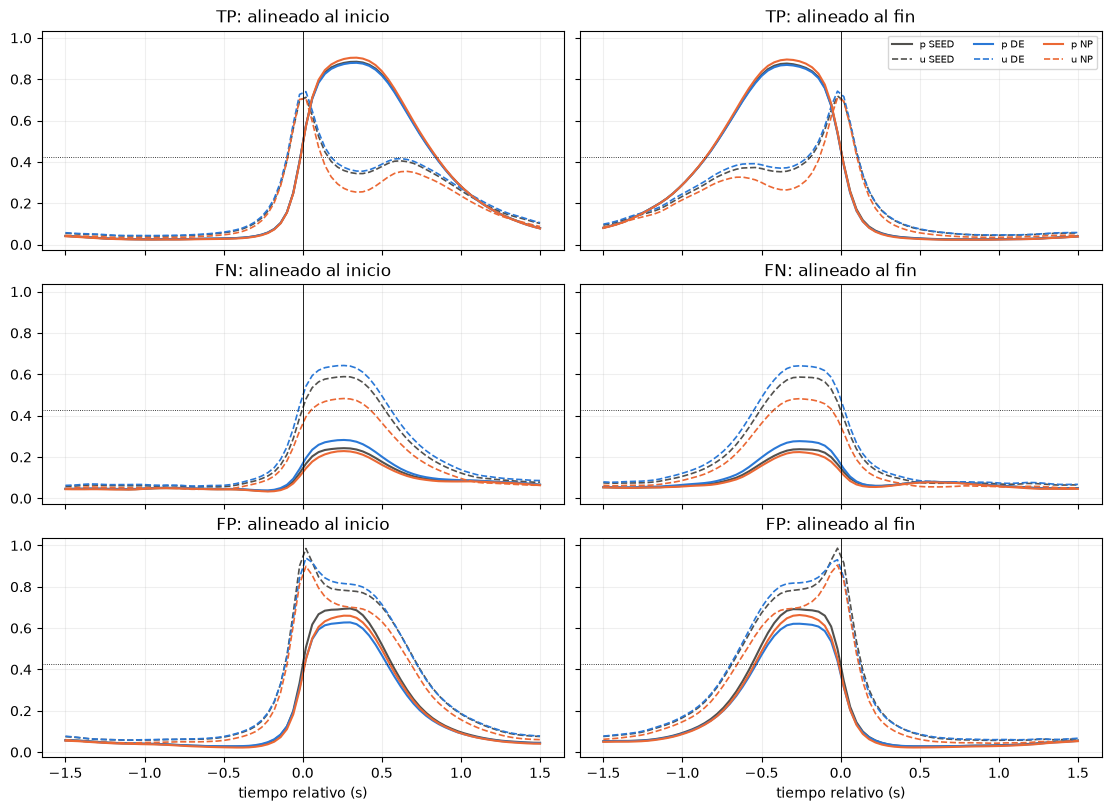

In [3]:
def curve(anchor, kind, name, cls='todos', stat='media'):
    table = result['aligned'][anchor]
    return table[(table['tipo'] == kind) & (table['clase duración'] == cls) & (table['serie'] == name)].iloc[0][stat]


fig, axes = plt.subplots(3, 2, figsize=(11, 8), sharex=True, sharey=True, constrained_layout=True)
for i, kind in enumerate(['TP', 'FN', 'FP']):
    for j, anchor in enumerate(['inicio', 'fin']):
        ax = axes[i, j]
        for model, p, u in [('SEED', 'p SEED', 'u SEED'), ('DE', 'p DE', 'u total DE'), ('NP', 'p NP', 'u total NP')]:
            ax.plot(OFFSETS, curve(anchor, kind, p), color=MODEL_COLORS[model], lw=1.5, label=f'p {model}')
            ax.plot(OFFSETS, curve(anchor, kind, u), color=MODEL_COLORS[model], lw=1.2, ls='--', label=f'u {model}')
        ax.axvline(0, color='black', lw=0.6)
        ax.axhline(DURATION_THRESHOLD, color='black', ls=':', lw=0.6)
        ax.set_title(f'{kind}: alineado al {anchor}')
        ax.grid(alpha=0.2)
axes[0, 1].legend(fontsize=7, ncol=3, loc='upper right')
for ax in axes[-1]:
    ax.set_xlabel('tiempo relativo (s)')
show(fig)

La **MI**, la parte epistémica, tiene otra escala. Va en su propio gráfico: media y rango intercuartil (sombra), con la probabilidad del DE como referencia (gris).

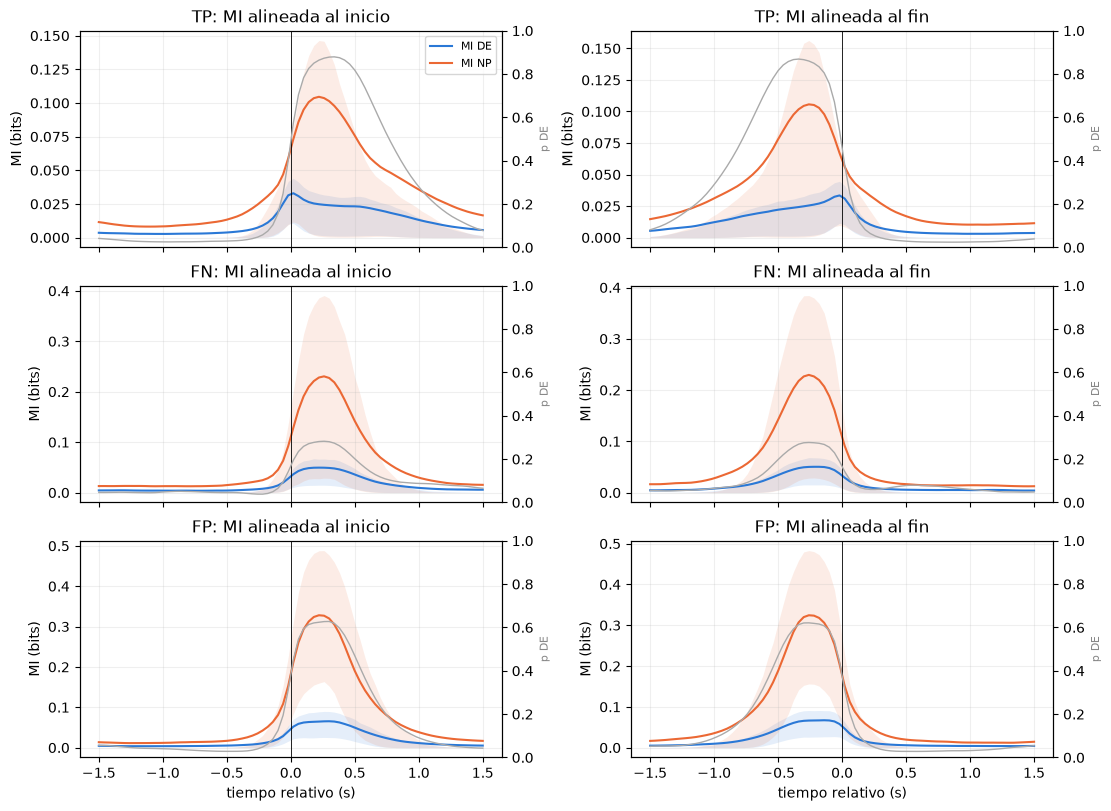

In [4]:
fig, axes = plt.subplots(3, 2, figsize=(11, 8), sharex=True, constrained_layout=True)
for i, kind in enumerate(['TP', 'FN', 'FP']):
    for j, anchor in enumerate(['inicio', 'fin']):
        ax = axes[i, j]
        for model, name in [('DE', 'MI DE'), ('NP', 'MI NP')]:
            ax.plot(OFFSETS, curve(anchor, kind, name), color=MODEL_COLORS[model], lw=1.5, label=name)
            ax.fill_between(OFFSETS, curve(anchor, kind, name, stat='q25'), curve(anchor, kind, name, stat='q75'),
                            color=MODEL_COLORS[model], alpha=0.12, lw=0)
        twin = ax.twinx()
        twin.plot(OFFSETS, curve(anchor, kind, 'p DE'), color='#aaaaaa', lw=1, ls='-')
        twin.set_ylim(0, 1)
        twin.set_ylabel('p DE', color='#888888', fontsize=8)
        ax.axvline(0, color='black', lw=0.6)
        ax.set_title(f'{kind}: MI alineada al {anchor}')
        ax.set_ylabel('MI (bits)')
        ax.grid(alpha=0.2)
axes[0, 0].legend(fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel('tiempo relativo (s)')
show(fig)

### 1.3 Trayectoria conjunta p → u

La misma dinámica, dibujada como trayectoria: cada curva recorre el tiempo de −1.5 s a +1.5 s alrededor del **inicio** del evento. El eje X es la probabilidad media y el eje Y la incertidumbre media; el círculo marca el inicio del evento.

**Ojo:** son **promedios** de muchos eventos. Aunque la entropía total sea una función de p instante a instante, el promedio de u no es función del promedio de p: por eso aparecen "lazos" incluso en la entropía total. Lo que sirve leer es la **altura relativa**: a una misma probabilidad media, ¿qué tipo de evento tiene más incertidumbre?

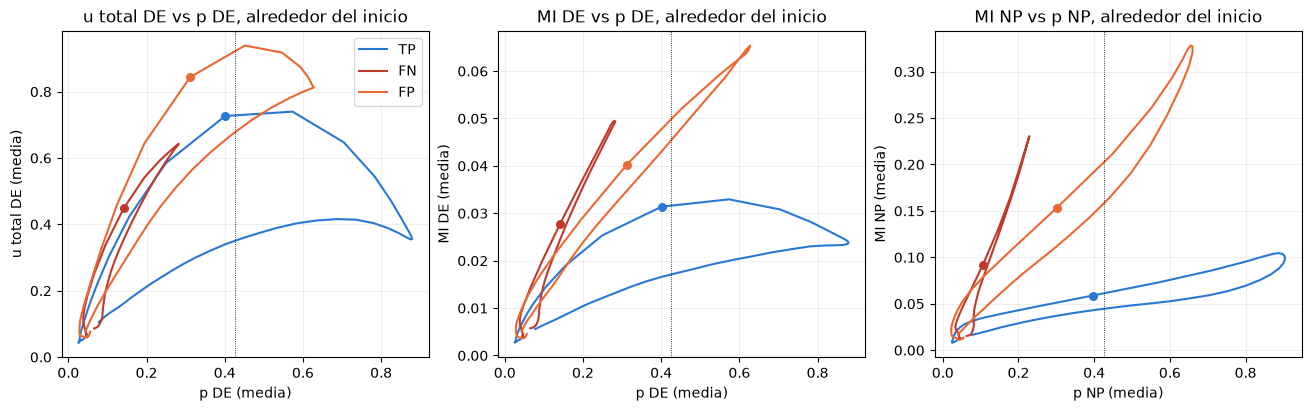

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
for ax, (u_name, p_name, label) in zip(axes, [('u total DE', 'p DE', 'u total DE'), ('MI DE', 'p DE', 'MI DE'), ('MI NP', 'p NP', 'MI NP')]):
    for kind in ['TP', 'FN', 'FP']:
        x, y = curve('inicio', kind, p_name), curve('inicio', kind, u_name)
        ax.plot(x, y, color=TYPE_COLORS[kind], lw=1.5, label=kind)
        zero = np.argmin(np.abs(OFFSETS))
        ax.scatter([x[zero]], [y[zero]], color=TYPE_COLORS[kind], s=30, zorder=3)
    ax.axvline(DURATION_THRESHOLD, color='black', ls=':', lw=0.6)
    ax.set_xlabel(f'{p_name} (media)')
    ax.set_ylabel(f'{label} (media)')
    ax.set_title(f'{label} vs {p_name}, alrededor del inicio')
    ax.grid(alpha=0.2)
axes[0].legend()
show(fig)

### 1.4 ¿Dónde tiene su pico la incertidumbre dentro del evento?

Posición del máximo de u dentro de cada evento: 0 = inicio, 0.5 = centro, 1 = fin.

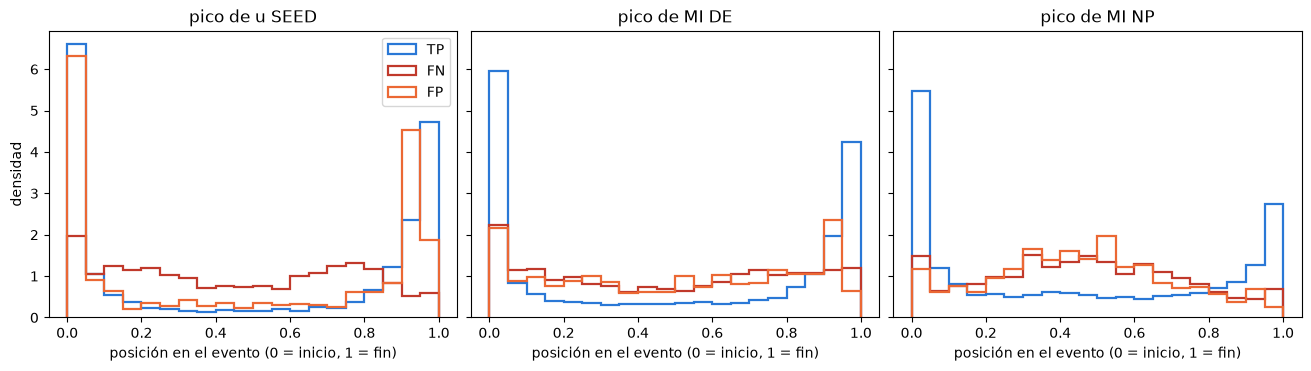

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True, constrained_layout=True)
bins = np.linspace(0, 1, 21)
for ax, name in zip(axes, ['u SEED', 'MI DE', 'MI NP']):
    for kind in ['TP', 'FN', 'FP']:
        values = events.loc[events['tipo'] == kind, f'posición pico {name}']
        ax.hist(values, bins=bins, density=True, histtype='step', lw=1.6, color=TYPE_COLORS[kind], label=kind)
    ax.set_title(f'pico de {name}')
    ax.set_xlabel('posición en el evento (0 = inicio, 1 = fin)')
axes[0].set_ylabel('densidad')
axes[0].legend()
show(fig)

### 1.5 ¿Qué tan atada está u a p?

Correlación de Spearman, instante por instante (200 000 instantes al azar por fold, promedio de los 15 folds):
- **u vs |p − 0.5|**: −1 significa que u es solo "qué tan cerca de 0.5 está p".
- **u del método vs u SEED**: cerca de 1 significa que el método duda donde mismo duda el SEED.

*Zona activa* = los instantes donde algún modelo da p ≥ 0.1. Fuera de ella casi todo es fondo, con p ≈ 0 y u ≈ 0, y eso infla las correlaciones.

In [7]:
corr = result['correlations'].groupby(['zona', 'medida', 'vs'], sort=False)['Spearman'].mean().unstack(0)
display(corr.round(3))

zona                         todos los instantes  zona activa (alguna p ≥ 0.1)
medida       vs                                                               
u SEED       |p SEED − 0.5|               -1.000                        -1.000
u total DE   |p DE − 0.5|                 -1.000                        -1.000
             u SEED                        0.973                         0.877
aleatoria DE |p DE − 0.5|                 -1.000                        -0.989
MI DE        |p DE − 0.5|                 -0.968                        -0.687
             u SEED                        0.927                         0.614
u total NP   |p NP − 0.5|                 -0.999                        -1.000
             u SEED                        0.805                         0.868
MI NP        |p NP − 0.5|                 -0.928                        -0.738
             u SEED                        0.768                         0.705

## 2. Incertidumbre por duración del evento

Cortes: **corto** < 0.6 s ≤ **mediano** < 0.9 s ≤ **largo**. Para TP y FN es la duración del huso anotado; para FP, la del tramo detectado.

In [8]:
MEASURES = ['u SEED', 'u total DE', 'MI DE', 'u total NP', 'MI NP']
spindles = events[events['tipo'] != 'TN']
medians = spindles.groupby(['clase duración', 'tipo'])[MEASURES].median().reindex(ud.DURATION_CLASSES, level=0)
counts = spindles.groupby(['clase duración', 'tipo']).size().rename('n')
display(pd.concat([counts, medians], axis=1).reindex(medians.index).round(3))

n  u SEED  u total DE  MI DE  u total NP  MI NP
clase duración tipo                                                    
corto          FN    1726   0.639       0.682  0.033       0.462  0.175
               FP    1486   0.970       0.945  0.055       0.902  0.360
               TP    3035   0.629       0.656  0.026       0.497  0.118
mediano        FN     750   0.616       0.684  0.032       0.474  0.179
               FP     888   0.793       0.867  0.048       0.718  0.220
               TP    5142   0.363       0.384  0.014       0.271  0.016
largo          FN     352   0.517       0.577  0.030       0.388  0.139
               FP     308   0.698       0.775  0.040       0.622  0.155
               TP    5018   0.292       0.311  0.012       0.244  0.013

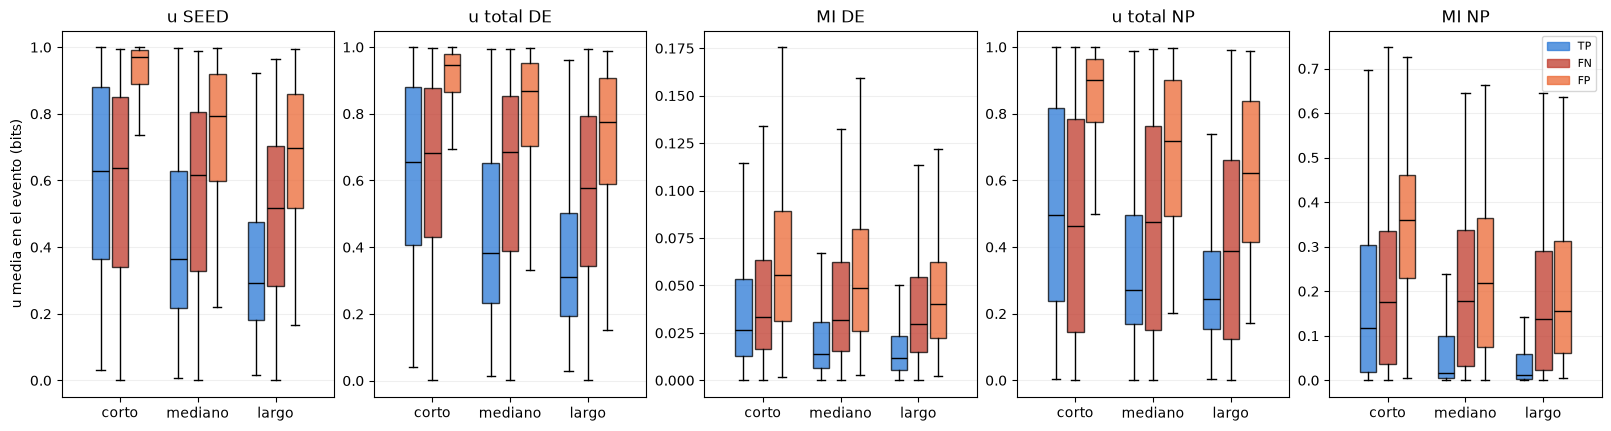

In [9]:
fig, axes = plt.subplots(1, len(MEASURES), figsize=(16, 4.2), constrained_layout=True)
positions, width = np.arange(len(ud.DURATION_CLASSES)), 0.25
for ax, name in zip(axes, MEASURES):
    for k, kind in enumerate(['TP', 'FN', 'FP']):
        data = [spindles.loc[(spindles['tipo'] == kind) & (spindles['clase duración'] == c), name] for c in ud.DURATION_CLASSES]
        box = ax.boxplot(data, positions=positions + (k - 1) * width, widths=width * 0.85, showfliers=False,
                         patch_artist=True, medianprops={'color': 'black'})
        for patch in box['boxes']:
            patch.set_facecolor(TYPE_COLORS[kind])
            patch.set_alpha(0.75)
    ax.set_xticks(positions, ud.DURATION_CLASSES)
    ax.set_title(name)
    ax.grid(axis='y', alpha=0.2)
axes[0].set_ylabel('u media en el evento (bits)')
axes[-1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=TYPE_COLORS[k], alpha=0.75) for k in ['TP', 'FN', 'FP']],
                labels=['TP', 'FN', 'FP'], fontsize=8)
show(fig)

**Masa de incertidumbre** (área bajo u(t) dentro del evento, bit·s). Crece con la duración simplemente porque hay más tiempo, por eso la comparación justa es **dentro** de cada clase.

In [10]:
mass = spindles.groupby(['clase duración', 'tipo'])[[f'masa {m}' for m in MEASURES]].median()
display(mass.reindex(ud.DURATION_CLASSES, level=0).round(4))

masa u SEED  masa u total DE  masa MI DE  masa u total NP  masa MI NP
clase duración tipo                                                                       
corto          FN         0.2781           0.2958      0.0147           0.2018      0.0800
               FP         0.3990           0.3988      0.0249           0.3805      0.1566
               TP         0.2985           0.3063      0.0130           0.2407      0.0565
mediano        FN         0.4235           0.4678      0.0222           0.3351      0.1224
               FP         0.5388           0.5834      0.0330           0.4999      0.1522
               TP         0.2681           0.2797      0.0103           0.2007      0.0117
largo          FN         0.5805           0.6206      0.0355           0.4329      0.1552
               FP         0.7846           0.8662      0.0481           0.7259      0.1831
               TP         0.3510           0.3700      0.0140           0.2894      0.0150

Dinámica promedio de los **TP** según su duración: probabilidad y MI del DE alineadas al inicio.

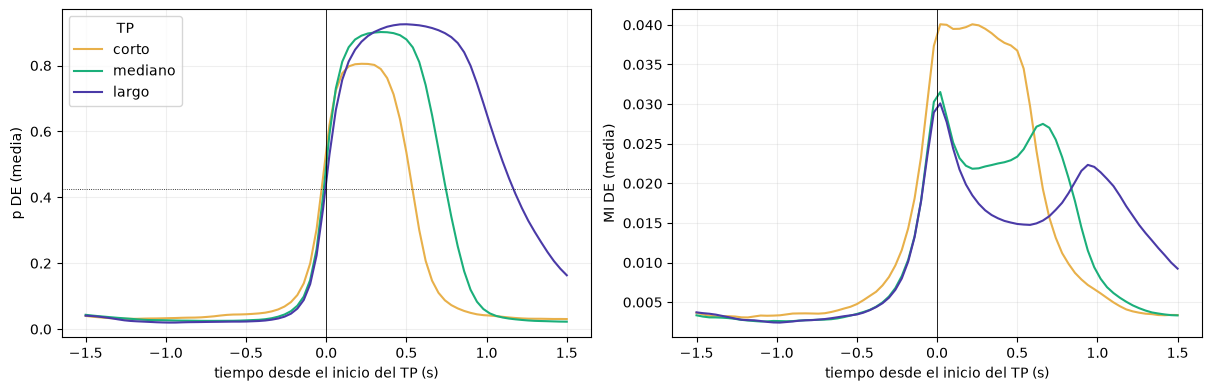

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
for cls in ud.DURATION_CLASSES:
    axes[0].plot(OFFSETS, curve('inicio', 'TP', 'p DE', cls), color=DURATION_COLORS[cls], lw=1.5, label=cls)
    axes[1].plot(OFFSETS, curve('inicio', 'TP', 'MI DE', cls), color=DURATION_COLORS[cls], lw=1.5, label=cls)
axes[0].axhline(DURATION_THRESHOLD, color='black', ls=':', lw=0.6)
axes[0].set_ylabel('p DE (media)')
axes[1].set_ylabel('MI DE (media)')
for ax in axes:
    ax.axvline(0, color='black', lw=0.6)
    ax.set_xlabel('tiempo desde el inicio del TP (s)')
    ax.grid(alpha=0.2)
axes[0].legend(title='TP')
show(fig)

## 3. Pair plots: nuestra incertidumbre vs la del SEED base

Cada punto es un evento. Variables: `u SEED` (SEED base), `u total DE`, `MI DE` y `MI NP`.
- **Bajo la diagonal**: dispersión (hasta 1 500 puntos por color, al azar).
- **Diagonal**: histograma de cada variable.
- **Sobre la diagonal**: Spearman por color.

**Cómo leerlo:** si los puntos caen sobre una línea, el método duda donde mismo duda el SEED. Eso es la **suma cero**. Si se abren, hay eventos donde el método duda y el SEED no: lo que **podría rescatarse**.

### 3.1 Uno por tipo de evento (TP, FP, FN, TN del SEED base), coloreado por duración

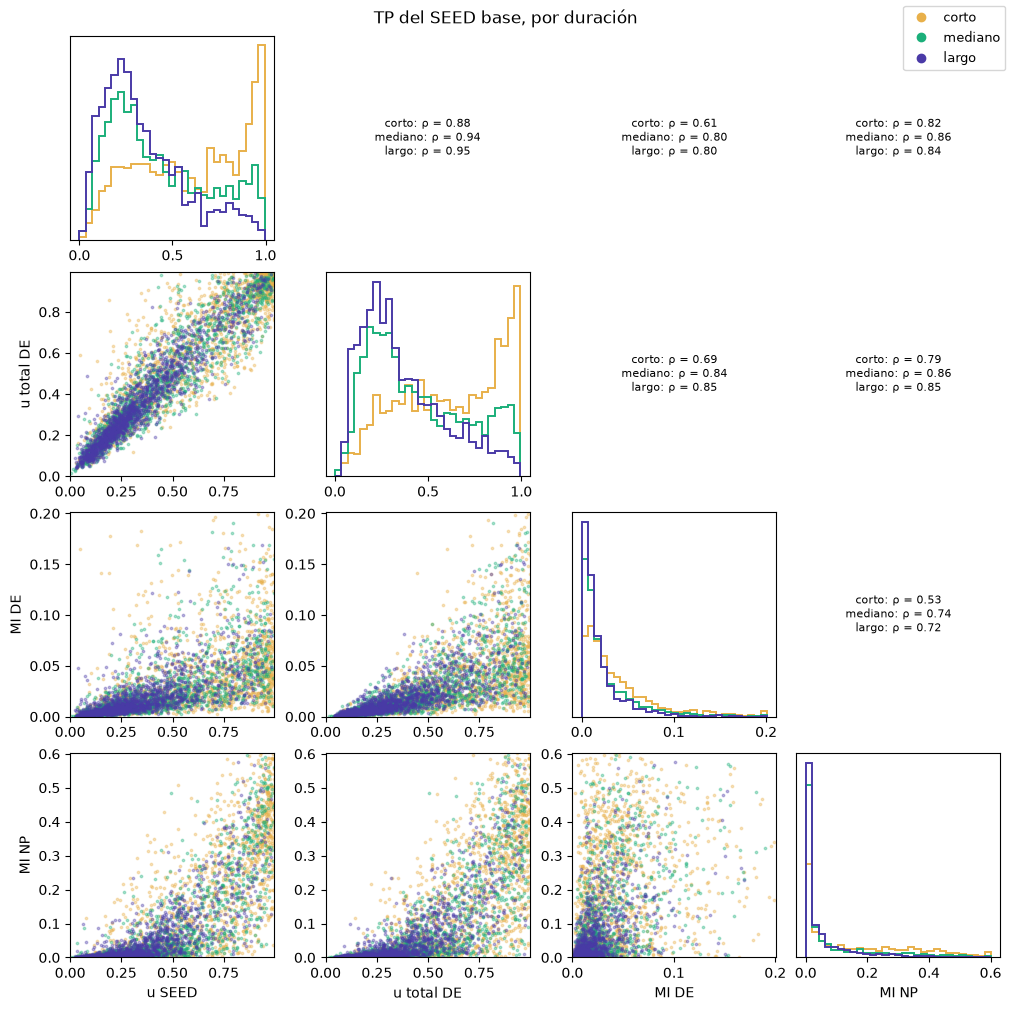

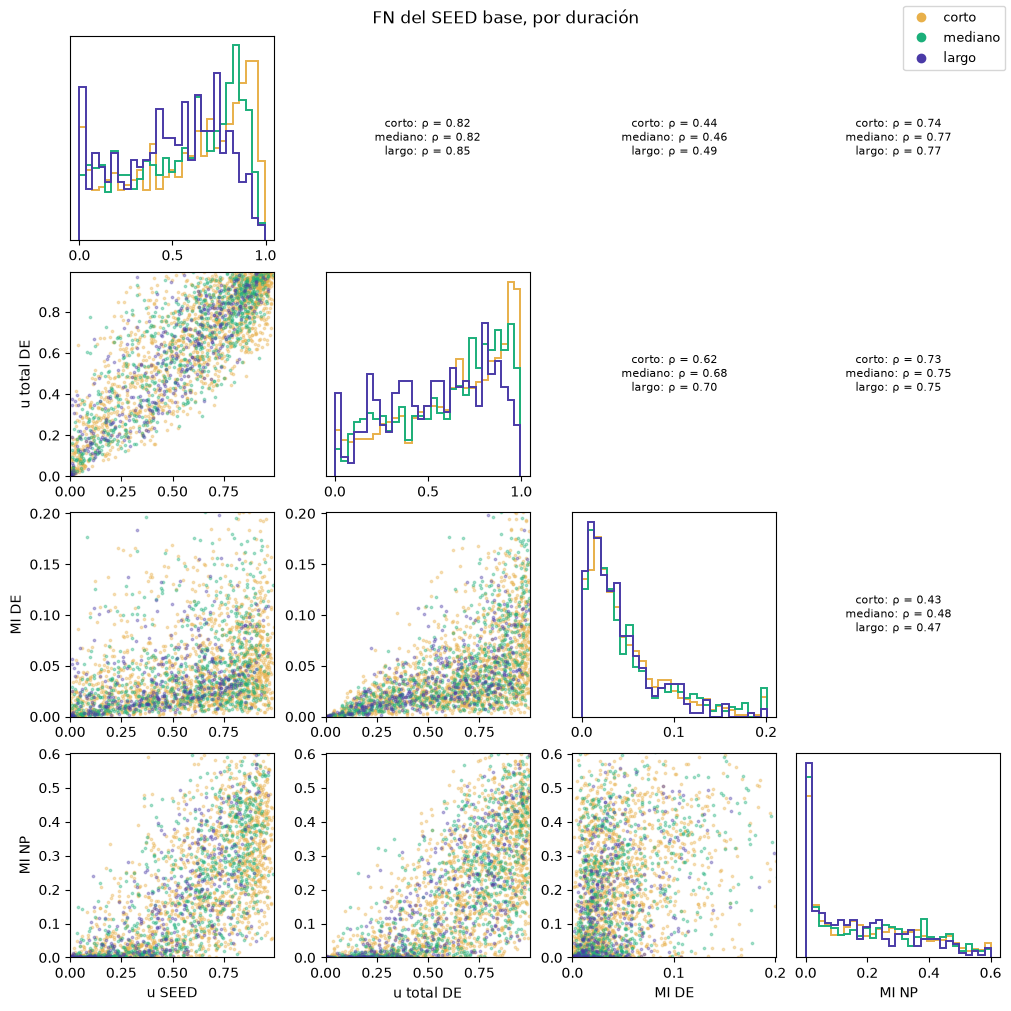

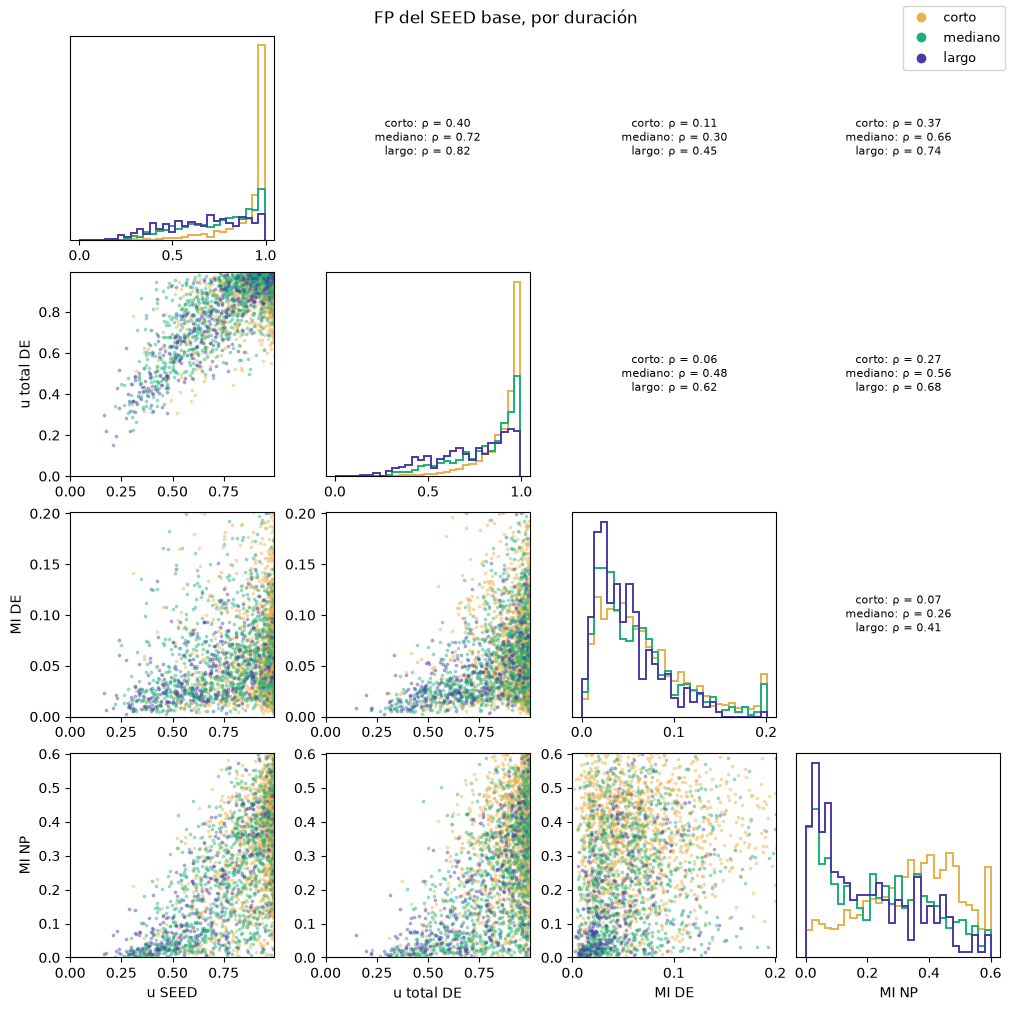

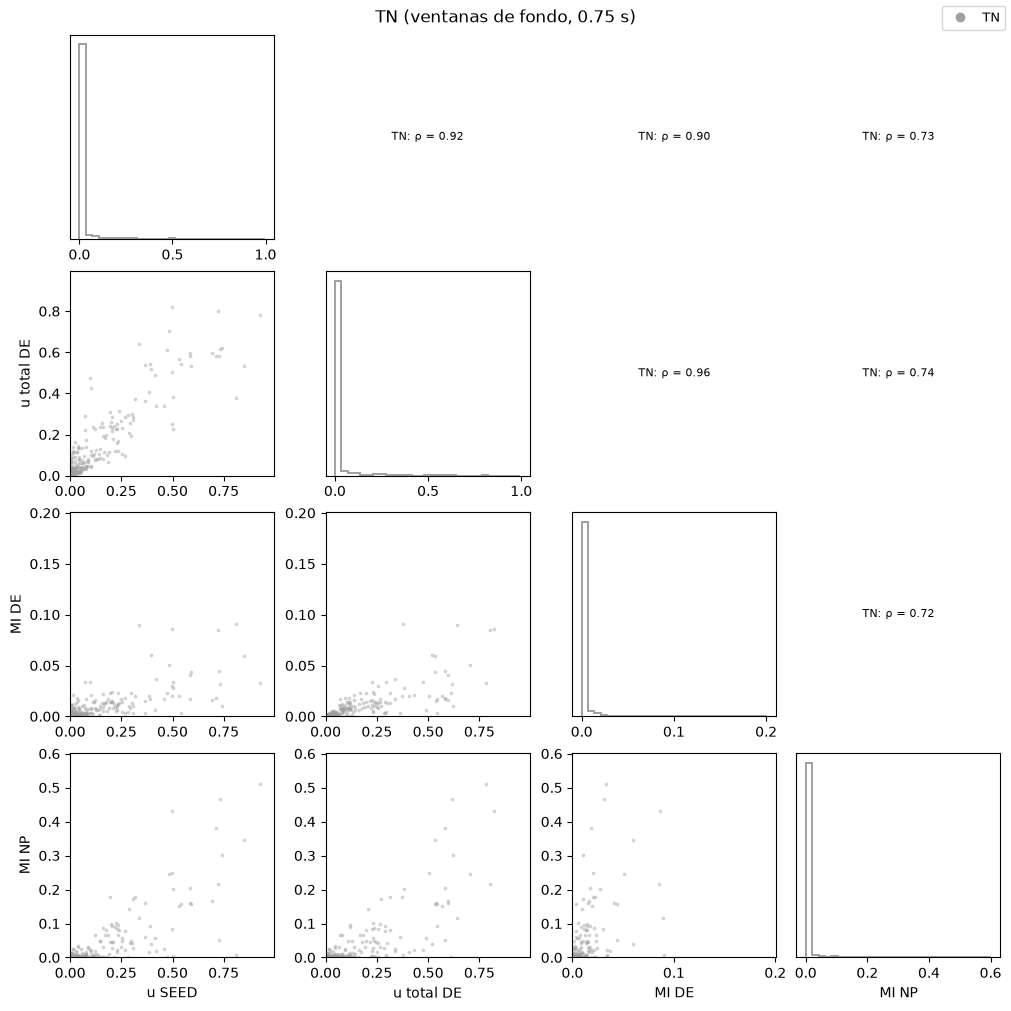

In [12]:
PAIR_VARS = ['u SEED', 'u total DE', 'MI DE', 'MI NP']
rng = np.random.default_rng(0)


def pairplot(data, hue, colors, title):
    n = len(PAIR_VARS)
    fig, axes = plt.subplots(n, n, figsize=(10, 10), constrained_layout=True)
    limits = {v: (0, max(1e-3, events[v].quantile(0.995))) for v in PAIR_VARS}
    groups = [(level, data[data[hue] == level]) for level in colors if (data[hue] == level).any()]
    groups = [(level, part.iloc[rng.permutation(len(part))[:1500]]) for level, part in groups]
    for i, yv in enumerate(PAIR_VARS):
        for j, xv in enumerate(PAIR_VARS):
            ax = axes[i, j]
            if i == j:
                bins = np.linspace(*limits[xv], 30)
                for level, part in groups:
                    ax.hist(part[xv].clip(*limits[xv]), bins=bins, density=True, histtype='step', lw=1.4, color=colors[level])
                ax.set_yticks([])
            elif i > j:
                for level, part in groups:
                    ax.scatter(part[xv], part[yv], s=3, alpha=0.35, color=colors[level], rasterized=True)
                ax.set_xlim(limits[xv])
                ax.set_ylim(limits[yv])
            else:
                ax.axis('off')
                lines = [f'{level}: ρ = {spearmanr(part[xv], part[yv]).statistic:.2f}' for level, part in groups if len(part) > 5]
                ax.text(0.5, 0.5, '\n'.join(lines), ha='center', va='center', fontsize=8, transform=ax.transAxes)
            if i == n - 1:
                ax.set_xlabel(xv)
            if j == 0 and i != 0:
                ax.set_ylabel(yv)
    handles = [plt.Line2D([], [], marker='o', ls='', color=colors[level], label=level) for level, _ in groups]
    fig.legend(handles=handles, loc='upper right', fontsize=9)
    fig.suptitle(title)
    show(fig)


for kind in ud.EVENT_TYPES:
    part = events[events['tipo'] == kind]
    if kind == 'TN':
        pairplot(part.assign(color='TN'), 'color', {'TN': TYPE_COLORS['TN']}, 'TN (ventanas de fondo, 0.75 s)')
    else:
        pairplot(part, 'clase duración', DURATION_COLORS, f'{kind} del SEED base, por duración')

### 3.2 Uno por duración (corto, mediano, largo), coloreado por tipo de evento

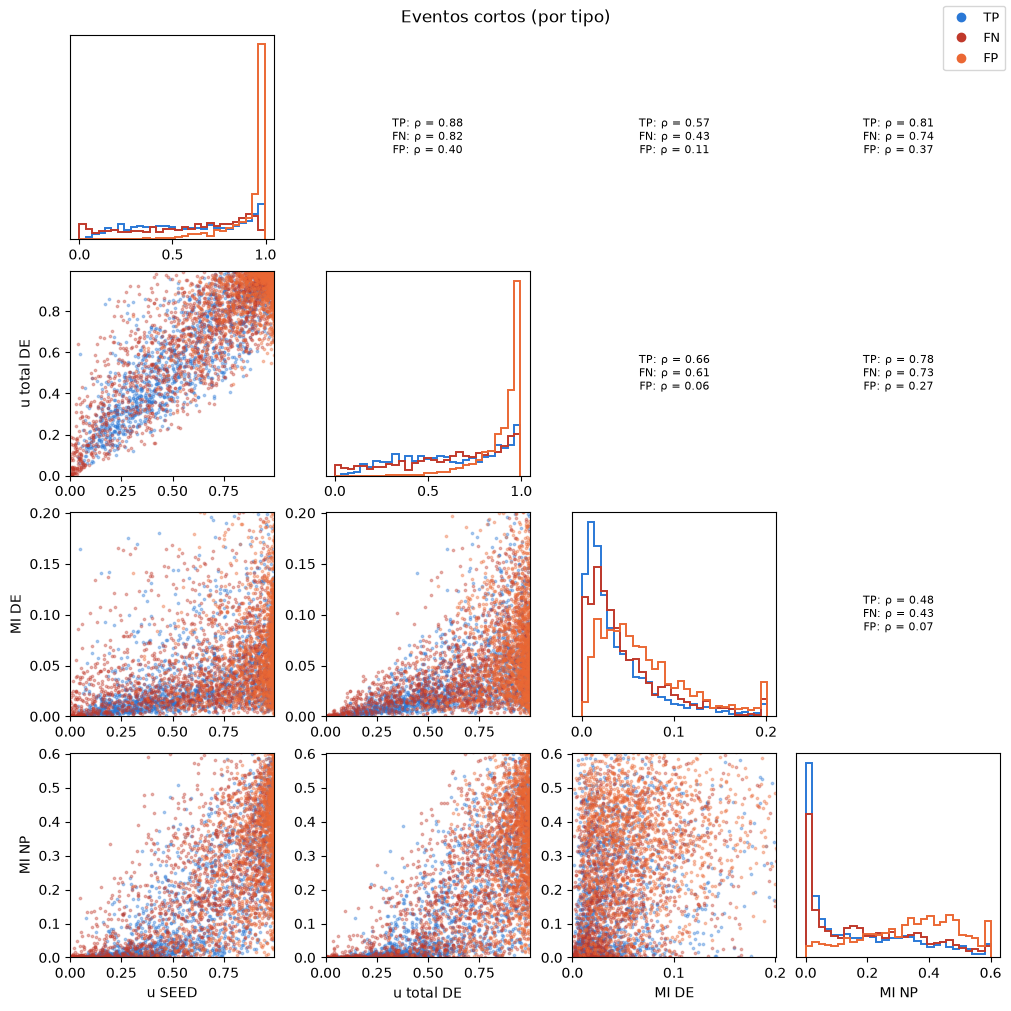

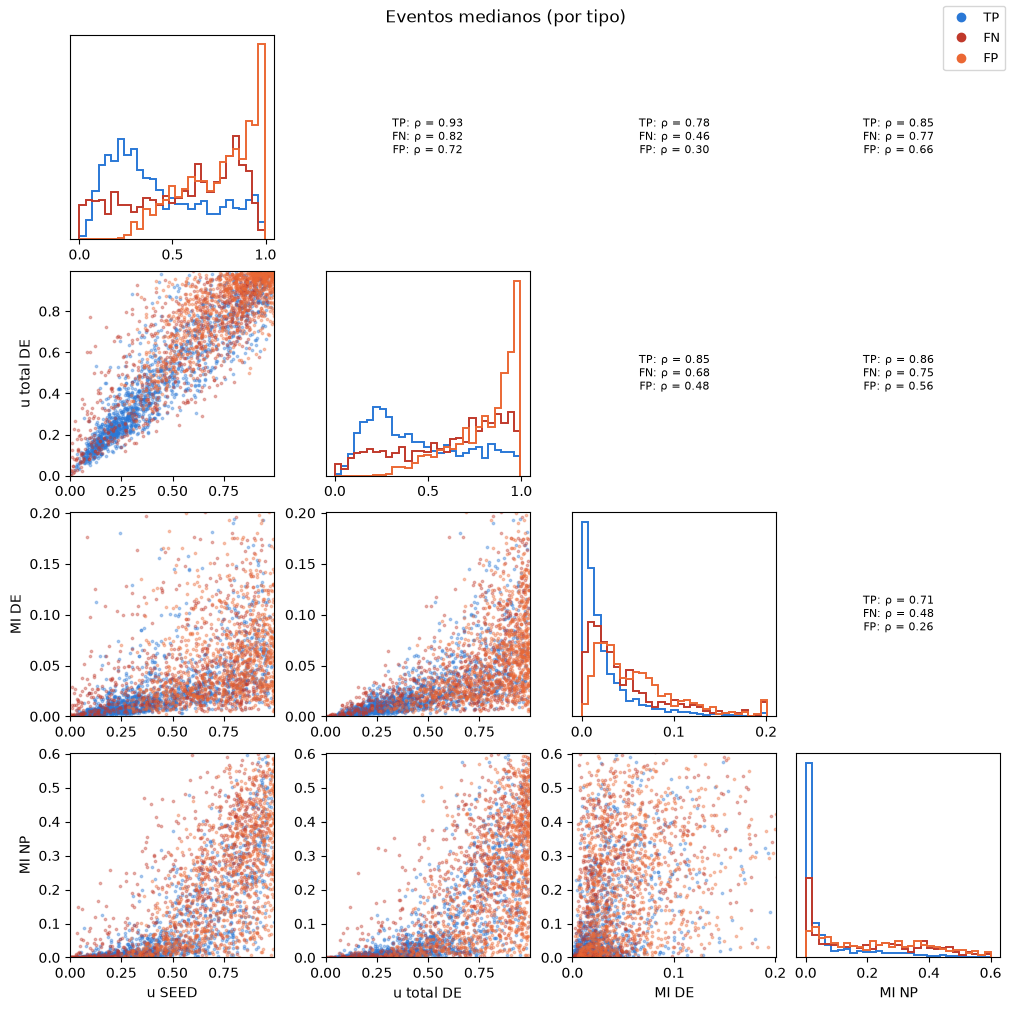

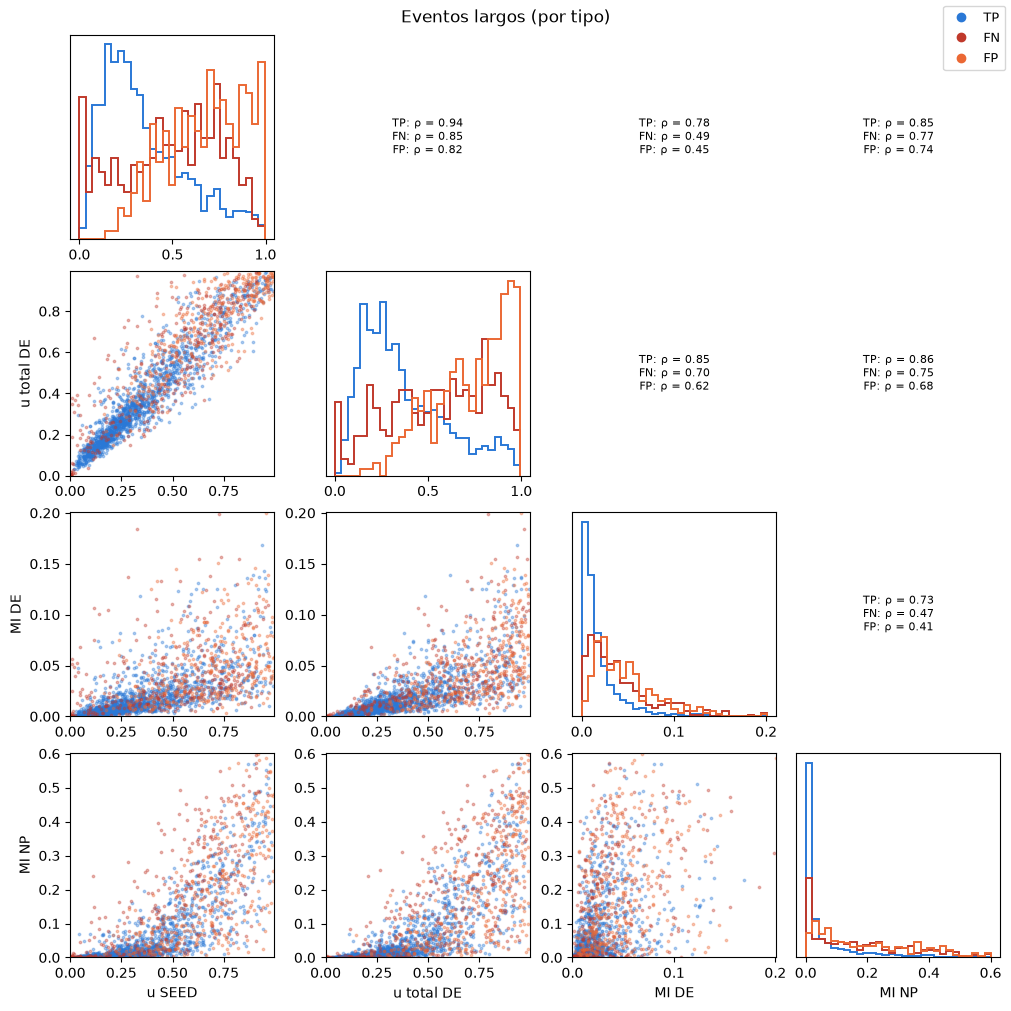

In [13]:
for cls in ud.DURATION_CLASSES:
    part = events[events['clase duración'] == cls]
    pairplot(part, 'tipo', {k: TYPE_COLORS[k] for k in ['TP', 'FN', 'FP']}, f'Eventos {cls}s (por tipo)')

### 3.3 ¿Suma cero o se rescata algo? En números

**Rescate.** Un evento está "en alerta" para una medida si su u está en el 20% más alto de esa medida (sobre todos los eventos). La tabla muestra, por tipo, en qué % de los eventos **solo el método** está en alerta (el SEED no) y en qué % **solo el SEED**. Lo útil sería un rescate alto en FN y FP, y bajo en TP.

In [14]:
rescue = ud.rescue_table(events)
display(rescue.set_index(['medida', 'tipo']).round(1))

n  % SEED alerta  % método alerta  % solo el método alerta (rescate)  % solo SEED alerta
medida     tipo                                                                                              
u total DE TP    13195           17.4             16.5                                3.3                 4.2
           FN     2828           31.7             33.9                               10.1                 7.9
           FP     2682           70.1             72.4                                9.3                 7.0
           TN     6741            0.2              0.1                                0.1                 0.1
MI DE      TP    13195           17.4             18.2                                8.3                 7.5
           FN     2828           31.7             38.6                               20.3                13.3
           FP     2682           70.1             57.5                               11.6                24.3
           TN     6741            0.2              0.8                                0.7                 0.1
u total NP TP    13195           17.4             17.3                                3.9                 4.0
           FN     2828           31.7             32.9                                9.4                 8.2
           FP     2682           70.1             69.2                                8.9                 9.8
           TN     6741            0.2              0.2                                0.1                 0.1
MI NP      TP    13195           17.4             16.5                                4.3                 5.3
           FN     2828           31.7             41.7                               16.9                 7.0
           FP     2682           70.1             63.4                                7.7                14.4
           TN     6741            0.2              0.5                                0.4                 0.0

**¿Agrega información?** AUROC para separar errores (FP o FN) de aciertos (TP) con la incertidumbre de cada evento:
- primero cada medida sola,
- luego `u SEED` combinada con la MI del DE o del NP en una regresión logística (se entrena con los otros 14 folds y se mide en el fold que queda fuera).

Si al combinar la AUROC **no sube** respecto a `u SEED` sola, el método no agrega nada: suma cero. Promedio de los 15 folds.

In [15]:
auroc = ud.error_auroc(events)
display(auroc.groupby('error vs TP').mean(numeric_only=True).drop(columns=['evaluación', 'fold']).round(3))

,u SEED,u total DE,MI DE,u total NP,MI NP,u SEED + MI DE,u SEED + MI NP,u SEED + MI DE + MI NP
error vs TP,,,,,,,,
FN vs TP,0.620,0.657,0.674,0.554,0.690,0.669,0.692,0.707
FP vs TP,0.879,0.878,0.804,0.857,0.843,0.878,0.877,0.878


Lo mismo **dentro de cada clase de duración**. Los FN son más cortos que los TP, y los eventos cortos son más inciertos. Así se descarta que la ganancia sea solo un efecto de la duración.

In [16]:
auroc_d = ud.error_auroc_by_duration(events)
table = auroc_d.groupby(['clase duración', 'error vs TP']).mean(numeric_only=True).drop(columns=['evaluación', 'fold'])
display(table.reindex(ud.DURATION_CLASSES, level=0).round(3))

u SEED  u total DE  MI DE  u total NP  MI NP  u SEED + MI DE  u SEED + MI NP  u SEED + MI DE + MI NP
clase duración error vs TP                                                                                                      
corto          FN vs TP      0.471       0.508  0.552       0.445  0.549           0.558           0.592                   0.599
               FP vs TP      0.859       0.818  0.711       0.801  0.781           0.854           0.854                   0.853
mediano        FN vs TP      0.620       0.660  0.683       0.564  0.706           0.676           0.705                   0.721
               FP vs TP      0.833       0.857  0.805       0.827  0.811           0.840           0.832                   0.840
largo          FN vs TP      0.648       0.682  0.706       0.556  0.718           0.702           0.710                   0.736
               FP vs TP      0.859       0.869  0.815       0.842  0.840           0.861           0.859                   0.861

## Hallazgos

1. **La incertidumbre total es casi una copia de la probabilidad.** En la zona activa, `u SEED`, `u total DE` y `u total NP` tienen correlación −1.00 con |p − 0.5|: no dicen nada que p no diga. Solo la **MI** tiene información propia (−0.69 en el DE, −0.74 en el NP).

2. **Dinámica conjunta: la duda está en los bordes del huso.**
   - En el SEED y el DE, la incertidumbre total y la MI tienen su **pico justo en el inicio y en el fin del evento**, donde p cruza el umbral. Bajan en el centro, cuando p es alta y estable: cada huso tiene "dos jorobas" de incertidumbre.
   - La **MI del NP** se comporta distinto: su pico está **dentro** del huso (~0.2 s después del inicio y antes del fin). El NP duda de la intensidad del huso, no tanto de dónde empieza.
   - En los **FN**, p nunca llega al umbral: la incertidumbre forma **una sola joroba** en el centro del huso.
   - En las trayectorias p → u, a **igual probabilidad media** los FN tienen más MI que los FP, y mucho más que los TP. Con la MI del NP y p ≈ 0.2: FN ≈ 0.2 bits, FP ≈ 0.1, TP ≈ 0.04. Son promedios, así que es una tendencia, no una regla por evento.

3. **Por duración: lo corto es incierto, sea acierto o error.**
   - Un **TP corto** tiene casi la misma incertidumbre que un FN (`u SEED` 0.63 vs 0.64).
   - En los **largos**, los TP están tranquilos (0.29) y los errores se distinguen mejor (FN 0.52, FP 0.70).
   - Parte de lo que mide la incertidumbre es "evento corto, casi todo borde", no "error".

4. **Pair plots: para los FP es suma cero; para los FN no.**
   - **FP:** la `u SEED` sola ya los separa de los TP (AUROC 0.88), y agregar la MI del DE o del NP no sube nada (0.88). El SEED ya sabe cuáles de sus detecciones son dudosas.
   - **FN:** sí se rescata algo. La `u SEED` separa poco los FN de los TP (0.62), pero al combinarla con la MI del DE y del NP sube a **0.71**. Se mantiene dentro de cada duración (medianos 0.62 → 0.72; largos 0.65 → 0.74). En la tabla de rescate, la MI del DE pone en alerta al 20% de los FN donde el SEED está tranquilo, contra solo 8% de los TP.

5. **Por qué eso no subió el F1 en los experimentos anteriores.** Esta comparación usa los **tramos anotados** de los FN, que el modelo no conoce al predecir. Para rescatar un FN primero hay que encontrarlo entre todas las zonas no detectadas, donde abundan las zonas dudosas sin huso. Ahí, en los experimentos 3–4, la MI separó mal (AUROC ~0.55). La información existe, pero queda diluida en el fondo.

**Siguiente paso posible: un score adaptativo que use la dinámica, no el valor puntual.** Por ejemplo, la forma de "dos jorobas" en los bordes, o la MI del NP alta *dentro* de una zona con p moderada, en vez de un umbral fijo sobre p. Se ajustaría en validación y se mediría en test contra el DE con 0.425.

*Cuidados*:
- Los TN son ventanas fáciles, lejos de cualquier evento.
- Las AUROC de FN vs TP se miden sobre husos anotados, no sobre el registro completo.
- Los ejemplos se eligen cerca de la mediana, no al azar.